In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

customers = pd.read_csv('../csv_files/olist_customers_dataset.csv')
order_items = pd.read_csv('../csv_files/olist_order_items_dataset.csv')
orders = pd.read_csv('../csv_files/olist_orders_dataset.csv')
products = pd.read_csv('../csv_files/olist_products_dataset.csv')
payments = pd.read_csv('../csv_files/olist_order_payments_dataset.csv')
reviews = pd.read_csv('../csv_files/olist_order_reviews_dataset.csv')
geolocation = pd.read_csv('../csv_files/olist_geolocation_dataset.csv')
sellers = pd.read_csv('../csv_files/olist_sellers_dataset.csv')
category_translation = pd.read_csv('../csv_files/product_category_name_translation.csv')


# Initial exploration of the dataset structure, shape, and missing values before any cleaning. 
# Lines commented out below were used for inspection and are kept for reference.

#category_translation.head()
#customers.tail()
#customers.shape
#customers.describe()
#reviews.info()
#payments.isnull().sum()

#Data cleanup: Convert all relevant date/time columns to datetime format

order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

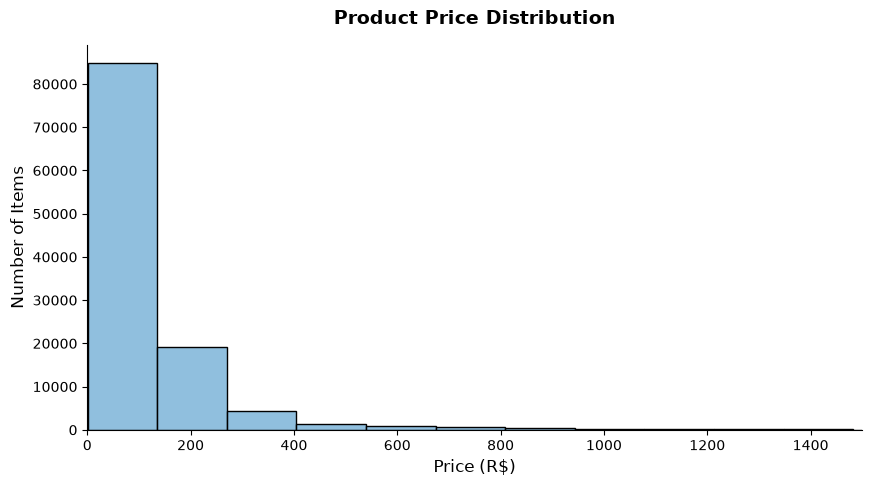

In [2]:
plt.figure(figsize=(10,5))
sns.histplot(data=order_items['price'], bins=50, color="#6baad4", edgecolor='black')
sns.despine()

plt.title('Product Price Distribution', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Price (R$)', fontsize=12)
plt.ylabel('Number of Items', fontsize=12)
plt.xlim(0, 1500)
plt.show()

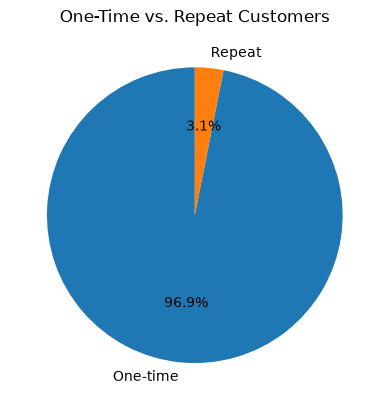

In [ ]:
orders_per_customer = (
    orders.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id')
    .groupby('customer_unique_id')['order_id'].nunique()
)

repeat_counts = pd.Series({
    'One-time': (orders_per_customer == 1).sum(),
    'Repeat': (orders_per_customer > 1).sum(),
})

fig, ax = plt.subplots()
ax.pie(repeat_counts, labels=repeat_counts.index, autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor': 'white'})
ax.set_title('One-Time vs. Repeat Customers')
plt.show()
